# 03 · Tune on dev

Settings are chosen on the **dev** split only (50 queries), never on test:
- **Input fields and truncation.** One shared text config for all methods, so every method sees the same text.
- **Stage-1 k** for the two-stage method.

The chosen settings are written to `v2/config.json`, which `04_test_runs` reads.

LLM cells need Jan's Local API Server running.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
BENCHES = ["random", "concept"]
TEXT_CONFIGS = [("t", 600), ("ta", 600), ("tac", 600)]
CHEAP_METHODS = ["bm25", "tfidf", "minilm", "specter2", "qwen", "embeddinggemma", "bge-reranker"]
RUN_LLM = True
STAGE1_KS = [10, 20, 30]

In [3]:
from src.pipeline_v2 import RunConfig, run_methods

results = []
for bench in BENCHES:
    for fields, max_chars in TEXT_CONFIGS:
        cfg = RunConfig(bench=bench, fields=fields, max_chars=max_chars, split="dev")
        results.append(run_methods(CHEAP_METHODS, cfg))
cheap = pd.concat(results)
cheap.pivot_table(index=["bench", "method"], columns="text_tag", values="rprec")

text_tag                t_600_1500  ta_600_1500  tac_600_1500
bench   method                                               
concept bge-reranker        66.254       59.476        55.688
        bm25                57.841       65.811        63.796
        embeddinggemma      75.317       82.267        80.344
        minilm              74.144       78.168        78.212
        qwen                81.936       81.219        81.323
        specter2            77.122       77.781        78.119
        tfidf               60.349       71.887        68.007
random  bge-reranker        74.930       69.838        70.200
        bm25                59.075       69.067        73.360
        embeddinggemma      84.154       87.192        88.362
        minilm              81.588       86.976        85.365
        qwen                88.166       88.245        88.713
        specter2            83.601       88.216        87.223
        tfidf               62.283       78.007        78.572

### Listwise LLM on dev (about 5 minutes per config and bench)

In [4]:
llm = []
if RUN_LLM:
    for bench in BENCHES:
        for fields, max_chars in TEXT_CONFIGS:
            cfg = RunConfig(bench=bench, fields=fields, max_chars=max_chars, split="dev")
            llm.append(run_methods(["llama"], cfg))
    llm = pd.concat(llm)
    display(llm[["bench", "text_tag", "mrr", "rprec", "ok", "partial", "failed", "sec_per_query"]])

,bench,text_tag,mrr,rprec,ok,partial,failed,sec_per_query
0,random,t_600_1500,0.693,55.180,32,15,3,1.558
0,random,ta_600_1500,0.679,45.310,28,21,1,4.039
0,random,tac_600_1500,0.722,46.889,24,24,2,7.020
0,concept,t_600_1500,0.645,48.698,30,13,7,3.191
0,concept,ta_600_1500,0.681,46.558,31,18,1,7.438
0,concept,tac_600_1500,0.670,43.610,28,20,2,9.157


### Choose the text config

Pick the config with the best mean rank across all methods on dev, both benchmarks together. Using one config for every method keeps the comparison fair.

In [5]:
# One row per (bench, config, method): average over seeds so extra runs cannot weight the choice.
dev = (pd.concat([cheap] + ([llm] if RUN_LLM else []))
       .groupby(["bench", "text_tag", "method"], as_index=False)[["mrr", "rprec"]].mean())
ranks = dev.groupby(["bench", "method"])["rprec"].rank(ascending=False)
mean_rank = ranks.groupby(dev["text_tag"]).mean().sort_values()
display(mean_rank.rename("mean rank (lower is better)").to_frame())
best_tag = mean_rank.index[0]
best_fields, best_max, _ = best_tag.split("_")
print("chosen text config:", best_tag)

,mean rank (lower is better)
text_tag,
tac_600_1500,1.750
ta_600_1500,1.875
t_600_1500,2.375


chosen text config: tac_600_1500


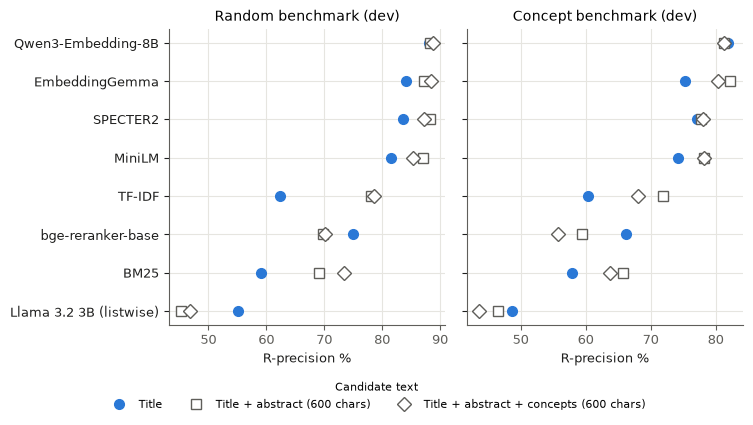

In [6]:
from src.figures import fig_dev_tuning
save(fig_dev_tuning(dev), "03_dev_tuning")

**Figure (03_dev_tuning).** Dev-split R-precision for each method under each text config (`t` = title, `a` = abstract, `c` = concepts; number = characters kept per candidate). Test queries are never used for this choice.

### Stage-1 k for two-stage (Qwen3 → Llama), with the chosen text config

In [7]:
two_stage = []
if RUN_LLM:
    for bench in BENCHES:
        for k in STAGE1_KS:
            cfg = RunConfig(bench=bench, fields=best_fields, max_chars=int(best_max), split="dev", stage1_k=k)
            two_stage.append(run_methods(["qwen→llama"], cfg).assign(k=k))
    two_stage = pd.concat(two_stage)
    display(two_stage[["bench", "k", "mrr", "rprec", "partial", "sec_per_query"]])
    best_k = int(two_stage.groupby("k")["rprec"].mean().idxmax())
else:
    best_k = 20
print("chosen stage-1 k:", best_k)

,bench,k,mrr,rprec,partial,sec_per_query
0,random,10,0.890,78.442,0,3.262
0,random,20,0.650,54.169,8,5.478
0,random,30,0.608,43.612,12,6.989
0,concept,10,0.828,70.892,0,3.442
0,concept,20,0.587,46.771,11,3.830
0,concept,30,0.598,40.587,16,3.592


chosen stage-1 k: 10


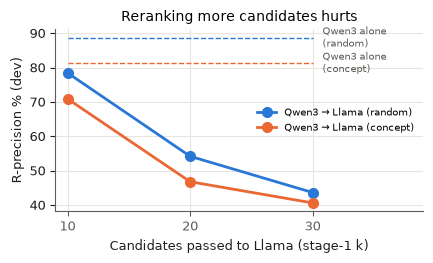

In [8]:
from src.figures import fig_stage1_k
if RUN_LLM:
    qwen_alone = {b: cheap[(cheap["bench"] == b) & (cheap["method"] == "qwen") & (cheap["text_tag"] == best_tag)]["rprec"].iloc[0]
                  for b in BENCHES}
    save(fig_stage1_k(two_stage, qwen_alone), "03_stage1_k")

**Figure (03_stage1_k).** Two-stage R-precision on dev against the number of stage-1 candidates Llama reranks. Dashed lines show Qwen3 alone, i.e. no reranking. Each extra candidate given to Llama lowers the score, and even at k = 10 reranking is below stage 1 alone.

In [9]:
import json
config = {"fields": best_fields, "max_chars": int(best_max), "query_max_chars": 1500, "stage1_k": best_k,
          "chosen_on": "dev", "dev_mean_rank": mean_rank.round(3).to_dict()}
(RESEARCH / "v2" / "config.json").write_text(json.dumps(config, indent=2))
config

{'fields': 'tac',
 'max_chars': 600,
 'query_max_chars': 1500,
 'stage1_k': 10,
 'chosen_on': 'dev',
 'dev_mean_rank': {'tac_600_1500': 1.75,
  'ta_600_1500': 1.875,
  't_600_1500': 2.375}}

### Sliding-window listwise Llama (RankGPT-style)

The full-list Llama ranker breaks down on long lists: it copies the input order and stops early. The sliding-window variant never shows the model more than 10 candidates. Windows of 10, moving 5 at a time, are reranked from the bottom of the shuffled list to the top, so strong candidates bubble up. A 42-candidate pool needs 8 calls. It is evaluated here on dev with the chosen text config, next to full-list Llama and Qwen3.

In [10]:
window = []
if RUN_LLM:
    for bench in BENCHES:
        cfg = RunConfig(bench=bench, fields=best_fields, max_chars=int(best_max), split="dev")
        window.append(run_methods(["llama-window"], cfg))
    window = pd.concat(window)
    raw = pd.concat([cheap, llm])
    compare = raw[(raw["text_tag"] == best_tag) & (raw["seed"] == 0) & raw["method"].isin(["llama", "qwen", "bge-reranker"])]
    display(pd.concat([compare, window])[["bench", "method", "mrr", "rprec", "ok", "partial", "failed", "sec_per_query"]]
            .sort_values(["bench", "rprec"], ascending=[True, False]))

,bench,method,mrr,rprec,ok,partial,failed,sec_per_query
4,concept,qwen,1.000,81.323,50,0,0,0.000
0,concept,bge-reranker,0.859,55.688,50,0,0,0.292
0,concept,llama-window,0.768,53.639,49,1,0,6.801
0,concept,llama,0.670,43.610,28,20,2,9.157
4,random,qwen,1.000,88.713,50,0,0,0.000
0,random,bge-reranker,0.933,70.200,50,0,0,0.308
0,random,llama-window,0.840,53.953,49,1,0,6.196
0,random,llama,0.722,46.889,24,24,2,7.020


### Findings

- **Text config.** One shared candidate text was chosen by mean rank across all methods and both benchmarks: **title + abstract + concepts, 600 characters per candidate** (mean rank 1.75, vs 1.88 for title + abstract and 2.38 for title only). The margin is small. Abstracts mostly help the lexical methods (TF-IDF on `random`: 62.3 → 78.6), while Qwen3 barely changes (88.2–88.7).
- **Two methods get worse with more text.** bge-reranker drops from 74.9 to 70.2 on `random` and from 66.3 to 55.7 on `concept`; its 512-token limit truncates the long query-candidate pairs. Listwise Llama also does best with titles only.
- **Listwise Llama is the weakest method in every config.** R-precision is 44–55%, against 82–89% for Qwen3 and about 33% for a random ranking. Between 26% and 48% of its answers are partial rankings (the model stops listing candidates), and 1–7 of 50 per config do not parse.
- **Reranking hurts the two-stage pipeline.** Two-stage R-precision falls as Llama reranks more candidates: on `random` 78.4 → 54.2 → 43.6 for k = 10, 20, 30, and on `concept` 70.9 → 46.8 → 40.6. Even at k = 10 it stays below Qwen3 alone (88.7 / 81.3). **k = 10** is used on test because it is the least harmful setting, not because reranking helps.
- **`concept` is harder.** Every method scores lower on `concept` (Qwen3 88.7 → 81.3), and the lexical methods drop the most.
- **The sliding window helps Llama but does not close the gap.** Showing at most 10 candidates per call makes the output reliable: 199 of 200 window calls parse fully (full list: 26–48% partial). It also raises R-precision from 46.9 to 54.0 on `random` and from 43.6 to 53.6 on `concept`. It still ranks far below Qwen3 (88.7 / 81.3) and below bge-reranker (70.2 / 55.7). The first-shown candidate still ends up first in 40–52% of queries, so order copying remains. The variant is kept for the test runs as the strongest listwise setting.
- **Encoder fixes (2026-10-12).** SPECTER2 now uses its [CLS] token instead of mean pooling, and EmbeddingGemma runs with its two Dense projection layers. Both models gain, and now sit close to Qwen3 (title + abstract + concepts):
  - SPECTER2: 82.6 → 87.2 on `random`, 73.1 → 78.1 on `concept`.
  - EmbeddingGemma: 85.7 → 88.4 on `random`, 79.2 → 80.3 on `concept`.

  The chosen text config and k are unchanged.